In [2]:
# Устанавливаем yfinance БЕЗ обновления pandas и других зависимостей Colab
!pip install --quiet yfinance matplotlib --no-warn-conflicts

In [3]:
# Импорт библиотек
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

# Настройки отображения pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

# --- СПИСОК ТИКЕРОВ ---
# ВАЖНО:
#   • Американские компании — обычные тикеры: 'AAPL', 'MSFT', 'GOOGL' и т.п.
#   • Российские компании на Yahoo Finance торгуются с суффиксом .ME (Московская биржа),
#     например: SBER.ME (Сбербанк), GAZP.ME (Газпром), LKOH.ME (Лукойл).
#   • Тикер без суффикса (например, 'SBER') на Yahoo Finance НЕ найдётся.
TICKERS = ["AAPL", "MSFT", "SBER.ME"]

# Период загрузки: можно '1y' (год) или указать даты: start="2023-01-01", end="2024-01-01"
START_DATE = "2023-01-01"
END_DATE   = datetime.today().strftime("%Y-%m-%d")

print(f"Тикеры: {TICKERS}")
print(f"Период: {START_DATE} → {END_DATE}")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Тикеры: ['AAPL', 'MSFT', 'SBER.ME']
Период: 2023-01-01 → 2026-11-14


In [4]:
# --- ЗАГРУЗКА ИСТОРИЧЕСКИХ ДАННЫХ ПО ЦЕНАМ ---
# Оборачиваем каждый тикер в try-except, чтобы одна ошибка не сломала весь скрипт.

historical_data = {}   # сюда сложим DataFrame по каждому тикеру

for ticker in TICKERS:
    try:
        print(f"Загрузка цен для {ticker}...")
        df = yf.download(
            ticker,
            start=START_DATE,
            end=END_DATE,
            progress=False,
            auto_adjust=True,
        )

        # Проверяем, что данные действительно вернулись
        if df is None or df.empty:
            print(f"⚠️  По тикеру {ticker} данные не найдены — пропускаем.")
            continue

        # Оставляем только нужные колонки
        df = df[["Open", "High", "Low", "Close", "Volume"]].copy()
        historical_data[ticker] = df
        print(f"✅ {ticker}: загружено {len(df)} строк")

    except Exception as e:
        print(f"❌ Ошибка при загрузке {ticker}: {e}")

# --- СОХРАНЕНИЕ В CSV с MultiIndex (ticker, date) ---
if historical_data:
    # Объединяем все DataFrame в один с MultiIndex по тикерам
    combined = pd.concat(historical_data, axis=1)  # ключи — тикеры
    combined.to_csv("historical_prices.csv")
    print("\n💾 Исторические цены сохранены в historical_prices.csv")
    print(f"   Форма итоговой таблицы: {combined.shape}")
else:
    print("\n⚠️  Исторические данные не были загружены ни по одному тикеру.")

Загрузка цен для AAPL...
✅ AAPL: загружено 971 строк
Загрузка цен для MSFT...


ERROR:yfinance:$SBER.ME: possibly delisted; no price data found  (1d 2023-01-01 -> 2026-11-14)
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SBER.ME']: possibly delisted; no price data found  (1d 2023-01-01 -> 2026-11-14)


✅ MSFT: загружено 971 строк
Загрузка цен для SBER.ME...
⚠️  По тикеру SBER.ME данные не найдены — пропускаем.

💾 Исторические цены сохранены в historical_prices.csv
   Форма итоговой таблицы: (971, 10)


In [5]:
# --- ФУНДАМЕНТАЛЬНЫЕ ПОКАЗАТЕЛИ через Ticker.info ---
# У российских тикеров (.ME) поле info у Yahoo Finance часто пустое,
# поэтому обрабатываем отсутствующие значения через None.

fundamentals_rows = []

for ticker in TICKERS:
    try:
        print(f"Загрузка фундаментальных данных для {ticker}...")
        info = yf.Ticker(ticker).info

        row = {
            "ticker":         ticker,
            "marketCap":      info.get("marketCap"),        # рыночная капитализация
            "trailingPE":     info.get("trailingPE"),       # P/E по последним 12 мес.
            "dividendYield":  info.get("dividendYield"),    # дивидендная доходность
            "sector":         info.get("sector"),           # сектор
        }
        fundamentals_rows.append(row)
        print(f"✅ {ticker}: данные получены")

    except Exception as e:
        print(f"❌ Ошибка при получении info для {ticker}: {e}")
        # Всё равно добавляем строку с NaN, чтобы тикер не потерялся
        fundamentals_rows.append({
            "ticker": ticker,
            "marketCap": None,
            "trailingPE": None,
            "dividendYield": None,
            "sector": None,
        })

# --- СОХРАНЕНИЕ ---
fundamentals_df = pd.DataFrame(fundamentals_rows).set_index("ticker")
fundamentals_df.to_csv("fundamentals.csv")
print("\n💾 Фундаментальные показатели сохранены в fundamentals.csv")
display(fundamentals_df)

Загрузка фундаментальных данных для AAPL...
✅ AAPL: данные получены
Загрузка фундаментальных данных для MSFT...
✅ MSFT: данные получены
Загрузка фундаментальных данных для SBER.ME...
✅ SBER.ME: данные получены

💾 Фундаментальные показатели сохранены в fundamentals.csv


,marketCap,trailingPE,dividendYield,sector
ticker,,,,
AAPL,5177380175872,39.673720,0.30,Technology
MSFT,3890434801664,27.342380,0.75,Technology
SBER.ME,2997184102400,2.644841,NaN,Financial Services


In [7]:
# --- РАСЧЁТ СРЕДНЕЙ ДНЕВНОЙ ДОХОДНОСТИ И ВОЛАТИЛЬНОСТИ ---
# Доходность считаем как процентное изменение цены закрытия.
# Волатильность — стандартное отклонение дневной доходности.
#
# ВАЖНО: в новых версиях yfinance колонка Close может приходить как DataFrame
# (а не Series). Чтобы избежать ошибок, «сжимаем» её через .squeeze().

if historical_data:
    stats_rows = []
    for ticker, df in historical_data.items():
        # .squeeze() превращает DataFrame с одним столбцом в Series
        close = df["Close"].squeeze()

        # Дневная доходность (теперь это гарантированно Series)
        returns = close.pct_change().dropna()

        if len(returns) == 0:
            continue

        # .item() вытаскивает из результата одно число (а не Series)
        mean_ret = float(returns.mean())
        daily_vol = float(returns.std())
        annual_vol = daily_vol * (252 ** 0.5)  # ~годовая (252 торговых дня)

        stats_rows.append({
            "ticker":                ticker,
            "mean_daily_return":     mean_ret,
            "daily_volatility":      daily_vol,
            "annualized_volatility": annual_vol,
        })

    stats_df = pd.DataFrame(stats_rows).set_index("ticker")

    # Красивый вывод БЕЗ .style.format() — проще и надёжнее
    print("📈 Средняя дневная доходность и волатильность:\n")
    for ticker, row in stats_df.iterrows():
        print(f"  {ticker:8s} | "
              f"ср. дневная доходность: {row['mean_daily_return']:>8.4%} | "
              f"дневная волатильность: {row['daily_volatility']:>8.4%} | "
              f"годовая волатильность: {row['annualized_volatility']:>8.4%}")

    print("\n📋 Полная таблица (для сохранения/просмотра):")
    display(stats_df.style.format({
        "mean_daily_return":     "{:.4%}",
        "daily_volatility":      "{:.4%}",
        "annualized_volatility": "{:.4%}",
    }))

else:
    print("⚠️  Нет данных для анализа.")

📈 Средняя дневная доходность и волатильность:

  AAPL     | ср. дневная доходность:  0.1229% | дневная волатильность:  1.6202% | годовая волатильность: 25.7199%
  MSFT     | ср. дневная доходность:  0.0976% | дневная волатильность:  1.6696% | годовая волатильность: 26.5048%

📋 Полная таблица (для сохранения/просмотра):


,mean_daily_return,daily_volatility,annualized_volatility
ticker,,,
AAPL,0.1229%,1.6202%,25.7199%
MSFT,0.0976%,1.6696%,26.5048%


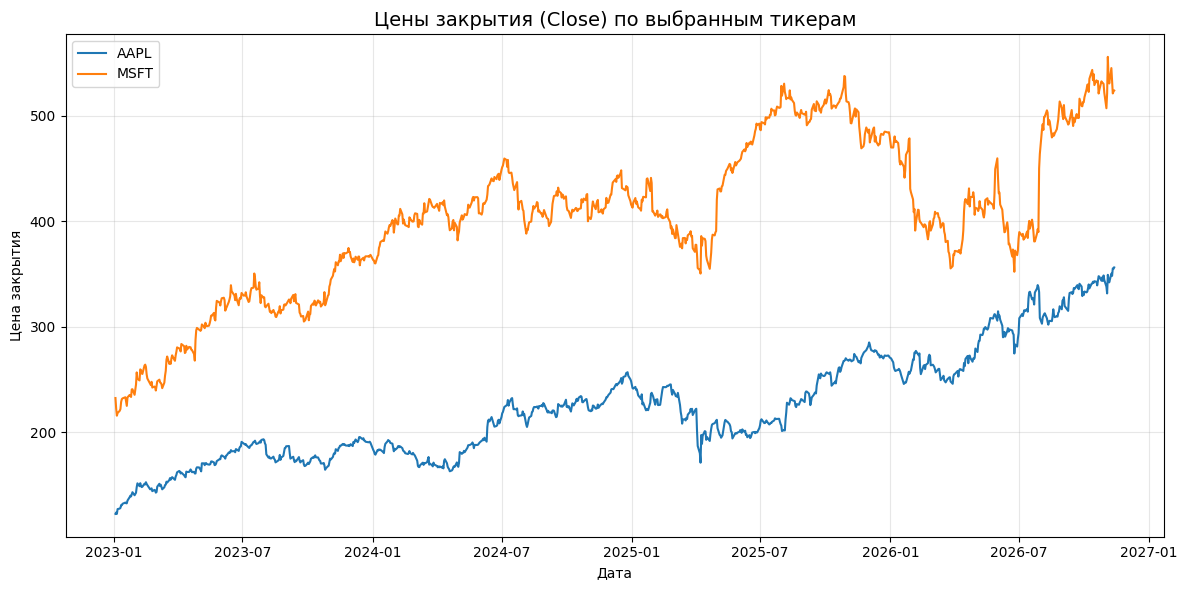

✅ График построен. Скрипт полностью выполнен 🎉


In [8]:
# --- ГРАФИК ЦЕН ЗАКРЫТИЯ ПО ВСЕМ ТИКЕРАМ ---
# Используем .squeeze(), чтобы колонка Close гарантированно была Series,
# а не DataFrame — иначе matplotlib может пожаловаться на размерность.

if historical_data:
    plt.figure(figsize=(12, 6))

    for ticker, df in historical_data.items():
        close = df["Close"].squeeze()   # ← страховка от «двумерной» Close
        plt.plot(close.index, close, label=ticker, linewidth=1.5)

    plt.title("Цены закрытия (Close) по выбранным тикерам", fontsize=14)
    plt.xlabel("Дата")
    plt.ylabel("Цена закрытия")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("✅ График построен. Скрипт полностью выполнен 🎉")
else:
    print("⚠️  Нет данных для построения графика.")

In [9]:
from google.colab import files
files.download("historical_prices.csv")
files.download("fundamentals.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
# Ячейка A — только первый файл
from google.colab import files
files.download("historical_prices.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>